In [1]:
import sys, os, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Markdown, display
import config
from src.utils import set_seed
set_seed(config.SEED)
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.facecolor": "#F5F1E8", "figure.facecolor": "#F5F1E8", "axes.edgecolor": "#77766D",
                     "font.size": 10, "axes.titleweight": "bold"})
PALETTE = ["#344C3D", "#BD755A", "#C4A46A", "#899982", "#77766D", "#242723"]
sns.set_palette(PALETTE)
def note(txt):  # data-driven observation rendered as markdown
    display(Markdown("> **Observation.** " + txt))

# 01 — Dataset Understanding

**Goal.** Before modelling anything, establish *what the data is*, where it comes from, under which terms it can be used and
what quality problems it has. MediScope uses three public biomedical resources, one per task:

| Task | Dataset | Notebook role |
|---|---|---|
| Sentence-role classification | **PubMed 20k RCT** | primary dataset (sections 1–7) |
| Biomedical NER | **BC5CDR** (T-NER sentence-split version) | section 8 |
| Summarization | **PubMed summarization** test split (Cohan et al.) | section 9 |

Every statistic printed below is computed from the files in `data/raw/` — nothing is typed in by hand.
Raw data is **not** committed to Git; `python -m src.data` re-creates it.

## 1. Source, licence and provenance

**PubMed 20k RCT** — Dernoncourt & Lee, *PubMed 200k RCT: a Dataset for Sequential Sentence Classification in Medical Abstracts*, IJCNLP 2017.
Download: `https://github.com/Franck-Dernoncourt/pubmed-rct` (folder `PubMed_20k_RCT/`). Each abstract of a randomized controlled trial is split into
sentences and every sentence carries one of five *rhetorical roles*: `BACKGROUND, OBJECTIVE, METHODS, RESULTS, CONCLUSIONS`.

**Licence — what is actually known.** The repository carries *no explicit licence file*. Its README explains that the data derive from the MEDLINE/PubMed
2016 baseline, that NLM states *"some abstracts may be protected by copyright"*, and that users are responsible for satisfying copyright terms.
MediScope therefore (a) uses the data for non-commercial research only, (b) never commits or redistributes it and (c) shows only short excerpts in the UI.

**BC5CDR** — BioCreative V Chemical-Disease Relation corpus (Li et al., *Database* 2016), obtained as the sentence-split `tner/bc5cdr` dataset.
The Hugging Face card lists `license: other`; same handling as above.

**PubMed summarization** — Cohan et al., NAACL 2018, via `ccdv/pubmed-summarization` (`document` config). The card declares no licence. Only the **test split**
(≈58 MB) is downloaded, for evaluation; the 2.2 GB training split is deliberately avoided.

> **Important design note.** PubMed RCT labels the *role of a sentence within an abstract* — it is **not** a topic-classification dataset. MediScope's
> "research category" is therefore the rhetorical role of each sentence, aggregated to an abstract-level structure view.

## 2. Loading and inspection

In [2]:
import src.data as D
train, dev, test = (D.load_pubmed_rct(s) for s in ("train", "dev", "test"))
splits = {"train": train, "dev": dev, "test": test}
shape_tbl = pd.DataFrame({
    "sentences": {k: len(v) for k, v in splits.items()},
    "abstracts": {k: v.abstract_id.nunique() for k, v in splits.items()},
    "columns": {k: v.shape[1] for k, v in splits.items()},
    "memory_MB": {k: round(v.memory_usage(deep=True).sum() / 1e6, 1) for k, v in splits.items()},
})
shape_tbl.loc["total"] = shape_tbl.sum(numeric_only=True)
shape_tbl

,sentences,abstracts,columns,memory_MB
train,180040,15000,5,37.5
dev,30212,2500,5,6.3
test,30135,2500,5,6.2
total,240387,20000,15,50.0


### Column description

| Column | Type | Meaning |
|---|---|---|
| `abstract_id` | string | PubMed ID of the abstract (parsed from the `###<id>` header line) |
| `sent_idx` | int | zero-based position of the sentence inside its abstract |
| `n_sents` | int | number of sentences of the abstract (added by `src.data`) |
| `label` | categorical (5) | **target** — rhetorical role of the sentence |
| `text` | string | the sentence |

In [3]:
train.dtypes.to_frame("dtype").join(train.nunique().to_frame("n_unique")).T

,abstract_id,sent_idx,n_sents,label,text
dtype,str,int64,int64,str,str
n_unique,15000,31,27,5,178882


### Sample records — one complete abstract

In [4]:
sample_id = train.abstract_id.iloc[0]
train[train.abstract_id == sample_id][["sent_idx", "label", "text"]]

,sent_idx,label,text
0,0,OBJECTIVE,"To investigate the efficacy of 6 weeks of daily low-dose oral prednisolone in improving pain , mobility , and system..."
1,1,METHODS,A total of 125 patients with primary knee OA were randomized 1:1 ; 63 received 7.5 mg/day of prednisolone and 62 rec...
2,2,METHODS,Outcome measures included pain reduction and improvement in function scores and systemic inflammation markers .
3,3,METHODS,Pain was assessed using the visual analog pain scale ( 0-100 mm ) .
4,4,METHODS,"Secondary outcome measures included the Western Ontario and McMaster Universities Osteoarthritis Index scores , pati..."
5,5,METHODS,"Serum levels of interleukin 1 ( IL-1 ) , IL-6 , tumor necrosis factor ( TNF ) - , and high-sensitivity C-reactive pr..."
6,6,RESULTS,"There was a clinically relevant reduction in the intervention group compared to the placebo group for knee pain , ph..."
7,7,RESULTS,"The mean difference between treatment arms ( 95 % CI ) was 10.9 ( 4.8-18 .0 ) , p < 0.001 ; 9.5 ( 3.7-15 .4 ) , p < ..."
8,8,RESULTS,"Further , there was a clinically relevant reduction in the serum levels of IL-1 , IL-6 , TNF - , and hsCRP at 6 week..."
9,9,RESULTS,These differences remained significant at 12 weeks .


## 3. Missing values and empty strings

In [5]:
miss = pd.DataFrame({k: v.isna().sum() for k, v in splits.items()})
empty = pd.Series({k: int((v.text.str.strip() == "").sum()) for k, v in splits.items()}, name="empty_text")
display(miss.T.assign(empty_text=empty))
short = train.text.str.split().str.len()
note(f"No missing values were found; {int((short <= 2).sum())} training sentences have two words or fewer "
     f"(e.g. {train.loc[short <= 2, 'text'].head(3).tolist()}). Such fragments carry almost no signal and are a source of irreducible error.")

,abstract_id,sent_idx,n_sents,label,text,empty_text
train,0,0,0,0,0,0
dev,0,0,0,0,0,0
test,0,0,0,0,0,0


> **Observation.** No missing values were found; 667 training sentences have two words or fewer (e.g. ['ISRCTN10858225 .', 'ACTRN12610000872033 .', 'no .']). Such fragments carry almost no signal and are a source of irreducible error.

## 4. Duplicates and leakage checks

Three different notions of "duplicate" matter and are checked separately:

1. **Structural duplicates** — the same `(abstract_id, sent_idx)` twice.
2. **Abstract-level leakage** — the same abstract appearing in more than one split. This would inflate test scores.
3. **Sentence-text overlap** — identical sentence strings across splits (boilerplate such as *"Not applicable."* can legitimately repeat; the question is *how much*).

In [6]:
struct_dups = {k: int(v.duplicated(["abstract_id", "sent_idx"]).sum()) for k, v in splits.items()}
ids = {k: set(v.abstract_id) for k, v in splits.items()}
leak = {f"{a}&{b}": len(ids[a] & ids[b]) for a, b in [("train", "dev"), ("train", "test"), ("dev", "test")]}
tr_text = set(train.text)
text_overlap = {k: float(v.text.isin(tr_text).mean()) for k, v in (("dev", dev), ("test", test))}
display(pd.DataFrame({"structural_duplicates": struct_dups}).T)
display(pd.DataFrame({"abstracts_shared": leak}).T)
dup_in_train = train.text.duplicated(keep=False)
label_conflict = (train[dup_in_train].groupby("text").label.nunique() > 1).sum()
note(f"Abstract-level leakage across splits is **{sum(leak.values())}**, so the official split is safe and no re-splitting is needed. "
     f"{text_overlap['test']:.2%} of test sentences also occur verbatim in train (mostly short boilerplate). "
     f"{int(dup_in_train.sum())} training rows belong to repeated sentence strings, and {int(label_conflict)} distinct strings carry *conflicting* labels — "
     f"a direct measure of label noise for context-free classifiers.")

,train,dev,test
structural_duplicates,0,0,0


,train&dev,train&test,dev&test
abstracts_shared,0,0,0


> **Observation.** Abstract-level leakage across splits is **0**, so the official split is safe and no re-splitting is needed. 1.01% of test sentences also occur verbatim in train (mostly short boilerplate). 1625 training rows belong to repeated sentence strings, and 44 distinct strings carry *conflicting* labels — a direct measure of label noise for context-free classifiers.

In [7]:
conflicts = (train[dup_in_train].groupby("text").label.agg(lambda s: dict(s.value_counts())).loc[lambda s: s.map(len) > 1])
conflicts.head(8).to_frame("label_counts")

,label_counts
text,
05 ) .,"{'RESULTS': 2, 'METHODS': 1}"
1 .,"{'METHODS': 5, 'RESULTS': 2, 'OBJECTIVE': 1, 'CONCLUSIONS': 1}"
2 .,"{'METHODS': 9, 'RESULTS': 2, 'OBJECTIVE': 1, 'CONCLUSIONS': 1}"
40 subjects with type 2 diabetes and moderate to severe CP were randomly distributed to groups receiving either NSPT or OHI .,"{'BACKGROUND': 1, 'METHODS': 1}"
Adverse events were monitored .,"{'METHODS': 1, 'OBJECTIVE': 1}"
Airway clearance was rapid .,"{'RESULTS': 1, 'CONCLUSIONS': 1}"
Baseline characteristics were similar in both groups .,"{'METHODS': 1, 'RESULTS': 1}"
Both treatments were well tolerated .,"{'RESULTS': 4, 'CONCLUSIONS': 2}"


## 5. Target distribution

,train,dev,test,train_%,dev_%,test_%
label,,,,,,
BACKGROUND,21727,3449,3621,12.07,11.42,12.02
OBJECTIVE,13839,2376,2333,7.69,7.86,7.74
METHODS,59353,9964,9897,32.97,32.98,32.84
RESULTS,57953,9841,9713,32.19,32.57,32.23
CONCLUSIONS,27168,4582,4571,15.09,15.17,15.17


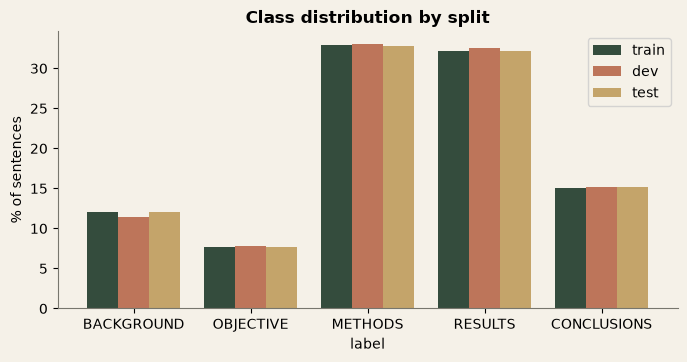

In [8]:
dist = pd.DataFrame({k: v.label.value_counts() for k, v in splits.items()}).reindex(config.CLASS_LABELS)
pct = (dist / dist.sum() * 100).round(2)
display(dist.join(pct, rsuffix="_%"))
fig, ax = plt.subplots(figsize=(8, 3.6))
pct.plot.bar(ax=ax, width=.8); ax.set_ylabel("% of sentences"); ax.set_title("Class distribution by split"); plt.xticks(rotation=0); plt.show()

A **chi-square test of homogeneity** asks whether the class mix differs between splits. If the official splits were drawn at random from the same population,
we expect no significant difference (but with 10⁴–10⁵ rows even tiny differences can become "significant", so we also report effect size via Cramér's V).

In [9]:
from scipy.stats import chi2_contingency
chi2, p, dof, _ = chi2_contingency(dist.values.T)
n = dist.values.sum(); cramers_v = np.sqrt(chi2 / (n * (min(dist.shape[::-1]) - 1)))
imb = dist["train"].max() / dist["train"].min()
note(f"chi² = {chi2:.1f}, dof = {dof}, p = {p:.3g}, Cramér's V = {cramers_v:.4f}. "
     f"Effect size is {'negligible' if cramers_v < .05 else 'noticeable'}, so train/dev/test have essentially the same class mix. "
     f"The training set is imbalanced: the largest class is {imb:.1f}× the smallest ({dist['train'].idxmax()} vs {dist['train'].idxmin()}), "
     f"which is why **macro-F1** is reported alongside accuracy throughout the project.")

> **Observation.** chi² = 11.8, dof = 8, p = 0.16, Cramér's V = 0.0050. Effect size is negligible, so train/dev/test have essentially the same class mix. The training set is imbalanced: the largest class is 4.3× the smallest (METHODS vs OBJECTIVE), which is why **macro-F1** is reported alongside accuracy throughout the project.

## 6. Structure of abstracts

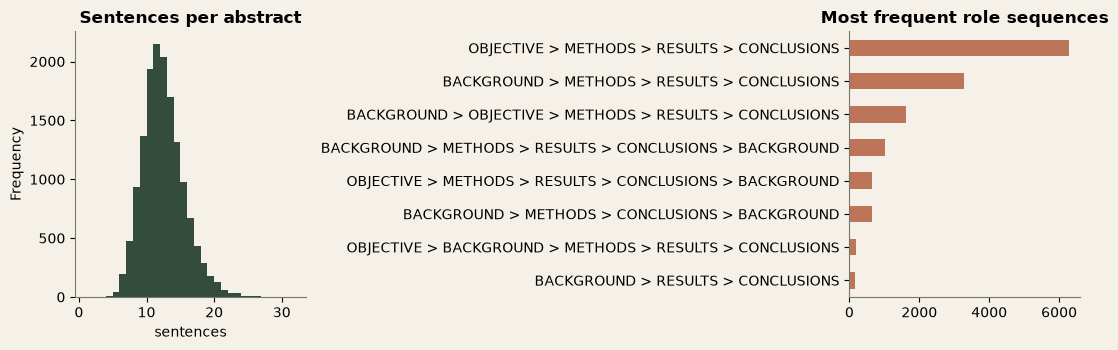

> **Observation.** Median abstract length is 12 sentences (IQR 10–14). 78.7% of abstracts follow the canonical order BACKGROUND→OBJECTIVE→METHODS→RESULTS→CONCLUSIONS without going backwards. Sentence **position** is therefore strongly informative about the label — a context-free sentence classifier cannot exploit it, which notebook 04 quantifies as an ablation.

In [10]:
per_abs = train.groupby("abstract_id").agg(n=("text", "size"), seq=("label", lambda s: tuple(s)))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
per_abs.n.plot.hist(bins=range(1, int(per_abs.n.max()) + 2), ax=axes[0], color=PALETTE[0]); axes[0].set_title("Sentences per abstract"); axes[0].set_xlabel("sentences")
collapsed = per_abs.seq.map(lambda s: " > ".join(k for i, k in enumerate(s) if i == 0 or s[i - 1] != k))
top = collapsed.value_counts().head(8)
top.sort_values().plot.barh(ax=axes[1], color=PALETTE[1]); axes[1].set_title("Most frequent role sequences"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()
order = {l: i for i, l in enumerate(config.CLASS_LABELS)}
mono = per_abs.seq.map(lambda s: all(order[a] <= order[b] for a, b in zip(s, s[1:]))).mean()
note(f"Median abstract length is {per_abs.n.median():.0f} sentences (IQR {per_abs.n.quantile(.25):.0f}–{per_abs.n.quantile(.75):.0f}). "
     f"{mono:.1%} of abstracts follow the canonical order BACKGROUND→OBJECTIVE→METHODS→RESULTS→CONCLUSIONS without going backwards. "
     f"Sentence **position** is therefore strongly informative about the label — a context-free sentence classifier cannot exploit it, "
     f"which notebook 04 quantifies as an ablation.")

## 7. Data-quality findings (PubMed 20k RCT)

In [11]:
findings = [
    f"No missing values; official split is abstract-disjoint (0 shared abstract IDs).",
    f"Class imbalance ≈ {imb:.1f}:1 between the largest and smallest class → use macro-F1, consider class weights.",
    f"Label noise floor: {int(label_conflict)} repeated sentence strings carry different labels.",
    f"Short fragments exist ({int((short <= 2).sum())} sentences ≤ 2 words).",
    f"Numbers were kept as in the original (the '@'-replaced variant is *not* used) because numeric tokens help detect RESULTS sentences.",
    "Sentence splitting was done by the dataset authors; abbreviations can produce occasional split errors that we cannot correct.",
    "Only randomized controlled trials are covered → results do not transfer automatically to other study designs (cohort, case report, reviews).",
]
display(Markdown("\n".join(f"- {f}" for f in findings)))

- No missing values; official split is abstract-disjoint (0 shared abstract IDs).
- Class imbalance ≈ 4.3:1 between the largest and smallest class → use macro-F1, consider class weights.
- Label noise floor: 44 repeated sentence strings carry different labels.
- Short fragments exist (667 sentences ≤ 2 words).
- Numbers were kept as in the original (the '@'-replaced variant is *not* used) because numeric tokens help detect RESULTS sentences.
- Sentence splitting was done by the dataset authors; abbreviations can produce occasional split errors that we cannot correct.
- Only randomized controlled trials are covered → results do not transfer automatically to other study designs (cohort, case report, reviews).

## 8. BC5CDR — NER dataset

BIO tags over word tokens. Entity types: `Chemical`, `Disease`. The T-NER release already split documents into sentences.

In [12]:
bc = {s: D.load_bc5cdr(s) for s in ("train", "dev", "test")}
rows = []
for s, recs in bc.items():
    from src.evaluation import bio_to_spans
    spans = [sp for r in recs for sp in bio_to_spans(r["tags"])]
    rows.append({"split": s, "sentences": len(recs), "tokens": sum(len(r["tokens"]) for r in recs),
                 "chemical_mentions": sum(1 for sp in spans if sp[0] == "Chemical"),
                 "disease_mentions": sum(1 for sp in spans if sp[0] == "Disease"),
                 "sentences_without_entity": sum(1 for r in recs if all(t == "O" for t in r["tags"]))})
bc_tbl = pd.DataFrame(rows).set_index("split"); display(bc_tbl)
tag_counts = pd.Series([t for r in bc["train"] for t in r["tags"]]).value_counts()
display(tag_counts.to_frame("train_token_count").assign(share=lambda d: (d.train_token_count / d.train_token_count.sum()).round(4)))

,sentences,tokens,chemical_mentions,disease_mentions,sentences_without_entity
split,,,,,
train,5228,109322,5203,4182,1313
dev,5330,108958,5347,4244,1441
test,5865,116318,5385,4424,1725


,train_token_count,share
O,96796,0.8854
B-Chemical,5203,0.0476
B-Disease,4182,0.0383
I-Disease,2570,0.0235
I-Chemical,571,0.0052


In [13]:
def mention_set(recs):
    out = set()
    for r in recs:
        for t, a, b in bio_to_spans(r["tags"]):
            out.add((t, " ".join(r["tokens"][a:b]).lower()))
    return out
tr_m, te_m = mention_set(bc["train"] + bc["dev"]), mention_set(bc["test"])
unseen = len(te_m - tr_m) / len(te_m)
lens = pd.Series([len(r["tokens"]) for r in bc["train"]])
note(f"{unseen:.1%} of the *distinct* test mentions never occur in train+dev. A pure dictionary lookup therefore has a hard recall ceiling of "
     f"≈{1 - unseen:.1%} on distinct mentions — this motivates a contextual transformer tagger. "
     f"Tag imbalance is extreme ('O' = {tag_counts['O'] / tag_counts.sum():.1%} of tokens), so token accuracy is meaningless and **entity-level F1** is used. "
     f"Sentences have a median of {lens.median():.0f} word tokens (95th percentile {lens.quantile(.95):.0f}), so `max_len=128` word-pieces is safe for nearly all.")

> **Observation.** 53.0% of the *distinct* test mentions never occur in train+dev. A pure dictionary lookup therefore has a hard recall ceiling of ≈47.0% on distinct mentions — this motivates a contextual transformer tagger. Tag imbalance is extreme ('O' = 88.5% of tokens), so token accuracy is meaningless and **entity-level F1** is used. Sentences have a median of 18 word tokens (95th percentile 46), so `max_len=128` word-pieces is safe for nearly all.

## 9. Summarization test split

Each record is a full article (`article`) and its author-written abstract (`abstract`) used as the **reference summary**.

shape: (6658, 5) | missing: 0 | duplicate articles: 2


,art_words,abs_words,compression
count,6658.000,6658.000,6658.000
mean,3092.234,205.353,0.099
std,2338.388,79.824,0.150
min,20.000,2.000,0.002
25%,1529.250,145.000,0.051
50%,2595.500,213.000,0.078
75%,3963.750,265.000,0.113
max,48750.000,506.000,6.550


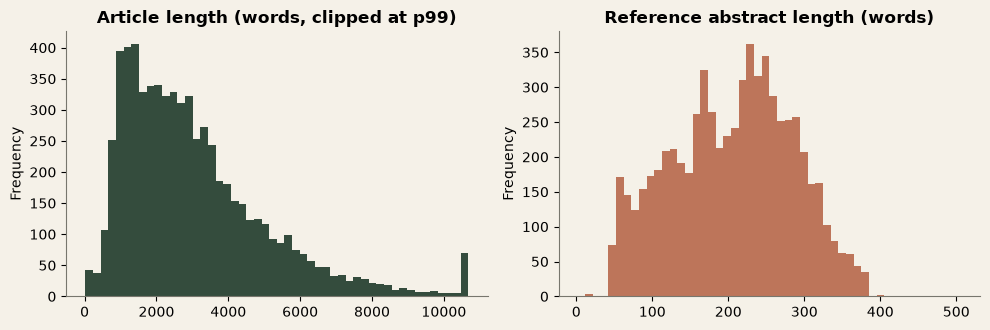

> **Observation.** Median article = 2596 words vs reference abstract = 213 words (median compression 7.8%). A T5-class encoder reads ≈512 tokens (~370 words), so 99.0% of articles exceed one encoder window → **long-document chunking is mandatory**, and any chunk-based summary sees only part of the evidence.

In [14]:
S = D.load_summarization_test()
S["art_words"] = S.article.str.split().str.len(); S["abs_words"] = S.abstract.str.split().str.len()
S["compression"] = S.abs_words / S.art_words
print("shape:", S.shape, "| missing:", int(S[["article", "abstract"]].isna().sum().sum()), "| duplicate articles:", int(S.article.duplicated().sum()))
display(S[["art_words", "abs_words", "compression"]].describe().round(3))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
S.art_words.clip(upper=S.art_words.quantile(.99)).plot.hist(bins=50, ax=ax[0], color=PALETTE[0]); ax[0].set_title("Article length (words, clipped at p99)")
S.abs_words.plot.hist(bins=50, ax=ax[1], color=PALETTE[1]); ax[1].set_title("Reference abstract length (words)")
plt.tight_layout(); plt.show()
note(f"Median article = {S.art_words.median():.0f} words vs reference abstract = {S.abs_words.median():.0f} words "
     f"(median compression {S.compression.median():.1%}). A T5-class encoder reads ≈512 tokens (~370 words), so {(S.art_words > 370).mean():.1%} of articles "
     f"exceed one encoder window → **long-document chunking is mandatory**, and any chunk-based summary sees only part of the evidence.")

## 10. Persist dataset statistics for the application

The Model Laboratory page and the *research fact of the day* read this small JSON file (derived statistics only; no corpus text is stored).

In [15]:
from src.utils import save_json
facts = [
    f"The median randomized-trial abstract in PubMed 20k RCT has {per_abs.n.median():.0f} sentences.",
    f"{dist['train'].idxmax().title()} sentences make up {pct['train'].max():.1f}% of the training corpus — the most common rhetorical role.",
    f"Only {pct['train'].min():.1f}% of sentences state the study objective ({dist['train'].idxmin().lower()}), the rarest role.",
    f"{mono:.0%} of abstracts present their sentences in the canonical Background→Objective→Methods→Results→Conclusions order.",
    f"{unseen:.0%} of distinct chemical/disease mentions in the BC5CDR test set never appear in the training data.",
    f"BC5CDR training sentences contain {int(bc_tbl.loc['train', 'chemical_mentions']):,} chemical and {int(bc_tbl.loc['train', 'disease_mentions']):,} disease mentions.",
    f"A typical article in the PubMed summarization benchmark has about {S.art_words.median():,.0f} words but its abstract only {S.abs_words.median():.0f}.",
]
stats = {
    "pubmed_rct": {"splits": {k: {"sentences": int(len(v)), "abstracts": int(v.abstract_id.nunique())} for k, v in splits.items()},
                    "class_distribution_train": {k: int(v) for k, v in dist["train"].items()},
                    "median_sentences_per_abstract": float(per_abs.n.median()), "canonical_order_share": float(mono),
                    "label_conflict_strings": int(label_conflict), "abstracts_shared_across_splits": int(sum(leak.values()))},
    "bc5cdr": bc_tbl.reset_index().to_dict("records"),
    "bc5cdr_unseen_test_mention_share": float(unseen),
    "summarization_test": {"articles": int(len(S)), "median_article_words": float(S.art_words.median()), "median_abstract_words": float(S.abs_words.median())},
    "facts": facts,
}
save_json(stats, config.ART_EVAL / "dataset_stats.json")
display(Markdown("\n".join(f"- {f}" for f in facts)))

- The median randomized-trial abstract in PubMed 20k RCT has 12 sentences.
- Methods sentences make up 33.0% of the training corpus — the most common rhetorical role.
- Only 7.7% of sentences state the study objective (objective), the rarest role.
- 79% of abstracts present their sentences in the canonical Background→Objective→Methods→Results→Conclusions order.
- 53% of distinct chemical/disease mentions in the BC5CDR test set never appear in the training data.
- BC5CDR training sentences contain 5,203 chemical and 4,182 disease mentions.
- A typical article in the PubMed summarization benchmark has about 2,596 words but its abstract only 213.

## Conclusions

* The PubMed 20k RCT split is clean structurally (no leakage, no missing values) but **imbalanced** and contains an irreducible label-noise floor for context-free models.
* The licence situation is *not* a permissive open licence: use is restricted to research, data stay out of Git, UI shows excerpts only.
* BC5CDR has many unseen test mentions, justifying contextual NER over dictionary lookup.
* Summarization articles far exceed a single encoder window, requiring chunking.

**Next:** notebook 02 explores the text itself (lengths, vocabulary, n-grams, medical terminology).